# 제품표 데이터 전처리: 결측치 처리와 정규화

RFP 기술 검토 에이전트가 판정 기준값으로 쓰는 제품표 `data/seed/products/product_master.csv`의 상태를 점검하고, 분석에 쓸 수 있는 정리본을 만듭니다.

- **데이터**: LS ELECTRIC 공개 카탈로그·인증서를 팀이 정리한 제품표 (122행 × 41열)
- **원칙**: 원본 파일은 바꾸지 않습니다. 정리본은 `results/`에 따로 저장합니다.
- **시스템 규칙과의 관계**: 에이전트는 판정할 때 원문 값과 원문 단위를 그대로 씁니다(단위 환산 안 함, CR-10). 이 노트북의 정규화는 제품끼리 비교하고 그림으로 보기 위한 **분석용**이며, 판정 로직에는 쓰지 않습니다.

순서
1. 불러오기와 첫 점검
2. 결측치: 현황 파악 → 원인별로 나누기 → 처리
3. 깨진 글자 복구
4. 형식 통일 (숫자형, 범위 값, 여러 값이 든 칸)
5. 일관성·이상치 점검
6. 정규화 (분석용)
7. 전처리 전후 품질 비교와 저장

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SRC = Path("../../data/seed/products/product_master.csv")
OUT = Path("results")
OUT.mkdir(exist_ok=True)

## 1. 불러오기와 첫 점검

빈 문자열을 결측(NaN)으로 읽습니다. 처음에는 모든 열을 문자열로 읽어, 숫자처럼 보이지만 형식이 섞인 값을 놓치지 않게 합니다.

In [2]:
raw = pd.read_csv(SRC, encoding="utf-8-sig", dtype=str, keep_default_na=False)
raw = raw.replace(r"^\s*$", np.nan, regex=True)  # 빈칸·공백만 있는 칸 → NaN
print(raw.shape)
raw["family"].value_counts()

(122, 41)


family
MV_EQUIP       97
SPD            20
GIS             4
TRANSFORMER     1
Name: count, dtype: int64

## 2. 결측치

### 2-1. 현황

In [3]:
missing = (
    raw.isna().mean().mul(100).round(1)
    .rename("missing_%").to_frame()
    .assign(missing_cells=raw.isna().sum())
    .sort_values("missing_%", ascending=False)
)
print(f"전체 결측 셀 비율: {raw.isna().mean().mean():.1%}")
missing[missing["missing_cells"] > 0]

전체 결측 셀 비율: 29.2%


,missing_%,missing_cells
has_firmware,100.0,122
fw_latest,100.0,122
ip_rating,100.0,122
dimensions_mm,100.0,122
list_price_usd,100.0,122
moq,100.0,122
std_lead_time_weeks,100.0,122
lifecycle_status,100.0,122
warranty_months,100.0,122
tech_support_dept,100.0,122


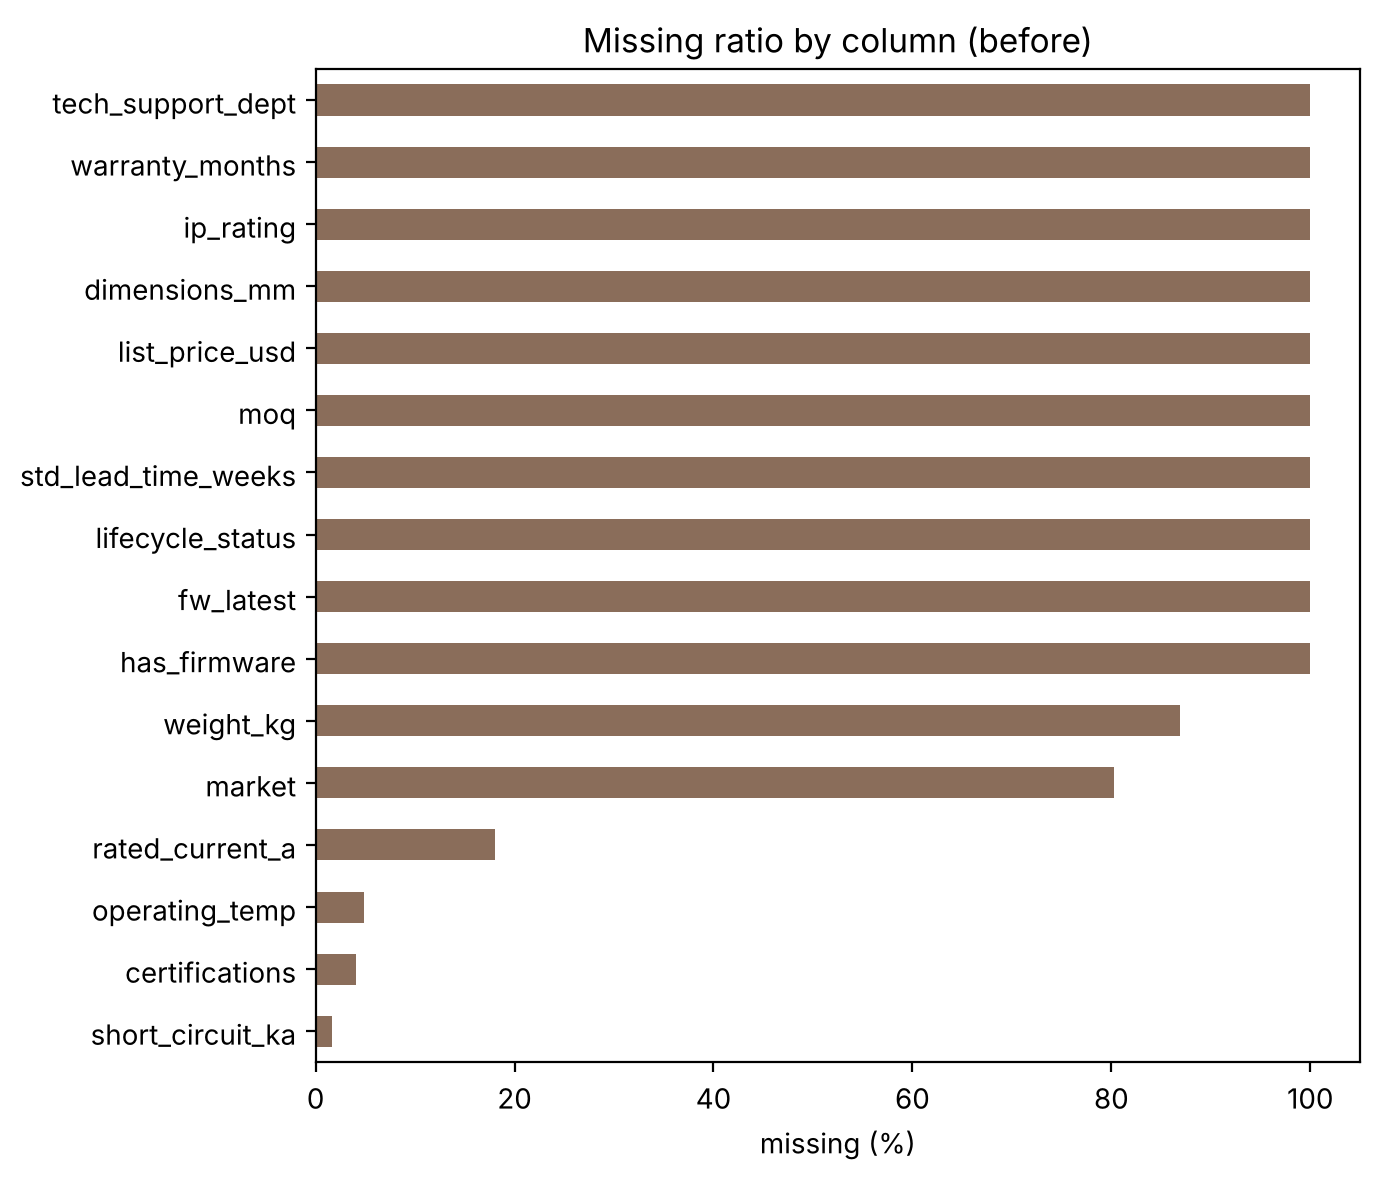

In [4]:
m = missing[missing["missing_cells"] > 0]["missing_%"].sort_values()
ax = m.plot.barh(figsize=(7, 6), color="#8a6d5a")
ax.set_xlabel("missing (%)")
ax.set_title("Missing ratio by column (before)")
plt.tight_layout()
plt.savefig(OUT / "missing_before.png", dpi=120)
plt.show()

### 2-2. 결측 원인별로 나누기

결측은 이유에 따라 처리 방법이 다릅니다. 같은 "빈칸"이라도 **값이 원래 없는 것**과 **값이 있는데 못 모은 것**은 구별해야 합니다.

| 유형 | 해당 열 | 이유 | 처리 |
|---|---|---|---|
| A. 수집 대상이 아닌 열 | 122행 모두 빈 열 | 제품표 양식에는 있지만 공개 카탈로그에 없는 항목(가격, 납기, 펌웨어 등) | 분석본에서 제외 |
| B. 구조적 결측 | SPD의 `rated_current_a` | 서지 보호기(SPD)는 정격 전류 대신 최대 방전 전류(Imax)로 사양을 표시함 | 채우지 않고 "해당 없음"으로 표시 |
| C. 수집 누락 | `weight_kg`, `certifications`, `market` 등 | 카탈로그에 값이 없거나 정리하지 못함 | 채우지 않고 "확인 필요"로 표시 |

사양값(무게, 정격 전류 등)을 평균이나 중앙값으로 채우면 **판정 근거가 지어낸 값이 됩니다.** 그래서 B, C는 값을 채우지 않고, 왜 비었는지를 나타내는 표시 열을 붙입니다.

In [5]:
# A. 122행 모두 빈 열
all_empty = raw.columns[raw.isna().all()].tolist()
print(len(all_empty), all_empty)

10 ['has_firmware', 'fw_latest', 'warranty_months', 'lifecycle_status', 'std_lead_time_weeks', 'moq', 'list_price_usd', 'dimensions_mm', 'ip_rating', 'tech_support_dept']


In [6]:
# B. SPD의 rated_current_a: 설명에 정격 전류(A) 대신 Imax(kA)가 적혀 있는지 확인
spd = raw[raw["family"] == "SPD"]
print("SPD 행 수:", len(spd))
print("rated_current_a 빈칸:", spd["rated_current_a"].isna().sum())
print("설명에 Imax 표기:", spd["description"].str.contains("Imax").sum())
spd[["product_code", "description"]].head(3)

SPD 행 수: 20
rated_current_a 빈칸: 20
설명에 Imax 표기: 20


,product_code,description
6,SPD-USPC-277Y100-T1-CAL,"Panel-type SPD, UL Type 1, 277/480V three-phas..."
7,SPD-USPC-277Y100-T2-CAL,"Panel-type SPD, UL Type 2, 277/480V three-phas..."
8,SPD-USPC-277Y150-T1-CAL,"Panel-type SPD, UL Type 1, 277/480V three-phas..."


In [7]:
# C. 그 밖의 결측을 제품군별로 보기
check_cols = ["rated_current_a", "short_circuit_ka", "weight_kg", "operating_temp", "certifications", "market"]
raw.groupby("family")[check_cols].agg(lambda s: s.isna().sum())

,rated_current_a,short_circuit_ka,weight_kg,operating_temp,certifications,market
family,,,,,,
GIS,0,0,4,4,3,0
MV_EQUIP,1,1,81,1,1,97
SPD,20,0,20,0,0,0
TRANSFORMER,1,1,1,1,1,1


`weight_kg`는 값이 있는 16행이 모두 UL 인증 VCB(`VCB-SUSOL-UL-*`)입니다. 다른 제품은 카탈로그에 무게가 없어 비어 있습니다. 같은 제품군 안에서도 정격 전류와 프레임에 따라 무게가 크게 다르므로(195~440 kg), 평균으로 채우지 않습니다.

In [8]:
raw.loc[raw["weight_kg"].notna(), ["product_code", "rated_current_a", "weight_kg"]]

,product_code,rated_current_a,weight_kg
26,VCB-SUSOL-UL-UVH-15H25C30,3000,260.0
27,VCB-SUSOL-UL-UVH-15H25L40,4000,440.0
28,VCB-SUSOL-UL-UVH-15H32C30,3000,260.0
29,VCB-SUSOL-UL-UVH-15H32L40,4000,440.0
30,VCB-SUSOL-UL-UVH-15H40A12,1200,195.0
31,VCB-SUSOL-UL-UVH-15H40A20,2000,210.0
32,VCB-SUSOL-UL-UVH-15H40C12,1200,210.0
33,VCB-SUSOL-UL-UVH-15H40C20,2000,225.0
34,VCB-SUSOL-UL-UVH-15H40C30,3000,260.0
35,VCB-SUSOL-UL-UVH-15H40L40,4000,440.0


In [9]:
df = raw.drop(columns=all_empty).copy()

# 결측 이유 표시 열
df["rated_current_status"] = np.select(
    [df["rated_current_a"].notna(), df["family"].eq("SPD")],
    ["value", "not_applicable"],
    default="needs_check",
)
for col in ["weight_kg", "certifications", "market", "operating_temp", "short_circuit_ka"]:
    df[f"{col}_missing"] = df[col].isna()

print(df.shape)
df["rated_current_status"].value_counts()

(122, 37)


rated_current_status
value             100
not_applicable     20
needs_check         2
Name: count, dtype: int64

## 3. 깨진 글자 복구

`operating_temp`에 `-40 to +75 째C`처럼 `째`가 들어 있습니다. UTF-8로 저장된 `°`(바이트 `C2 B0`)를 CP949로 잘못 읽은 뒤 다시 저장해서 생긴 문제입니다. CP949로 다시 인코딩한 다음 UTF-8로 읽으면 원래 글자로 돌아옵니다.

In [10]:
def fix_mojibake(s):
    if not isinstance(s, str) or "째" not in s:
        return s
    try:
        return s.encode("cp949").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

text_cols = [c for c in df.columns if df[c].map(lambda v: isinstance(v, str)).any()]
broken_before = int(df[text_cols].apply(lambda s: s.str.contains("째", na=False)).sum().sum())
for c in text_cols:
    df[c] = df[c].map(fix_mojibake)
broken_after = int(df[text_cols].apply(lambda s: s.str.contains("째", na=False)).sum().sum())

print("깨진 칸:", broken_before, "→", broken_after)
df["operating_temp"].dropna().unique()

깨진 칸: 116 → 0


<StringArray>
['-40 to +75 °C', '-40 to +40 °C', '-5 to +40 °C']
Length: 3, dtype: str

## 4. 형식 통일

### 4-1. 숫자 열
같은 값이 `125`와 `125.0`, `0.5`와 `0.5000`처럼 다르게 적혀 있습니다. 문자열로 비교하면 서로 다른 값으로 취급되므로 숫자형으로 바꿉니다.

In [11]:
num_cols = [
    "rated_voltage_kv", "rated_current_a", "short_circuit_ka", "weight_kg",
    "lightning_impulse_kv", "power_freq_withstand_kv", "switching_impulse_kv",
    "peak_current_ka", "making_current_ka", "breaking_time_ms", "closing_time_ms",
    "gas_leakage_percent", "partial_discharge_pc", "maintenance_months", "service_life_years",
]

# 문자열 기준으로 같은 값이 몇 가지 모양으로 적혀 있는지 센다
def format_variants(s):
    v = s.dropna()
    return int(v.nunique() - pd.to_numeric(v).nunique())

variants_before = {c: format_variants(df[c]) for c in num_cols}
print({k: v for k, v in variants_before.items() if v})

for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="raise")

df[num_cols].dtypes.value_counts()

{'peak_current_ka': 1, 'making_current_ka': 1}


float64    8
int64      7
Name: count, dtype: int64

### 4-2. 범위로 적힌 값 나누기

`-40 to +75 °C`를 최솟값과 최댓값 두 숫자 열로 나눕니다.

In [12]:
temp = df["operating_temp"].str.extract(r"(?P<temp_min_c>[-+]?\d+)\s*to\s*(?P<temp_max_c>[-+]?\d+)\s*°C")
df[["temp_min_c", "temp_max_c"]] = temp.astype(float)
df[["operating_temp", "temp_min_c", "temp_max_c"]].drop_duplicates().dropna()

,operating_temp,temp_min_c,temp_max_c
6,-40 to +75 °C,-40.0,75.0
26,-40 to +40 °C,-40.0,40.0
42,-5 to +40 °C,-5.0,40.0


### 4-3. 여러 값이 든 칸

`standards`, `certifications`, `market`은 `;`로 여러 값을 이어 적었습니다. 앞뒤 공백을 지우고 개수 열을 만듭니다.

In [13]:
for c in ["standards", "certifications", "market"]:
    parts = df[c].str.split(";").map(lambda xs: [x.strip() for x in xs if x.strip()] if isinstance(xs, list) else [])
    df[c] = parts.map(lambda xs: ";".join(xs) if xs else np.nan)
    df[f"{c}_count"] = parts.map(len)

df[["product_code", "standards", "standards_count", "certifications_count"]].head()

,product_code,standards,standards_count,certifications_count
0,GIS-170-50,ES-6110-0002;ES-5925-0001;IEC 62271-100;IEC 62...,4,1
1,GIS-145-40,IEC 62271-100;IEC 62271-203;IEC 62271-102,3,0
2,GIS-245-40,IEC 62271-100;IEC 62271-203;IEC 62271-102,3,0
3,GIS-245-50,IEC 62271-100;IEC 62271-203;IEC 62271-102,3,0
4,TRF-HV-OIL,IEC 60076;ANSI(IEEE) C57,2,0


## 5. 일관성·이상치 점검

전력 기기 사양에는 서로 맞아야 하는 값이 있습니다. 규칙으로 확인합니다.

- **투입 전류 = 피크 전류**: 차단기의 정격 투입 전류는 정격 피크 내전류와 같습니다.
- **피크 전류 ≈ 2.5 × 단시간 전류**: 50 Hz 기준 IEC 62271-1의 비율입니다. 반올림(31.25 → 31.3) 때문에 ±1%까지 허용합니다.
- **제품군 안 IQR 이상치**: 같은 제품군에서 사분위 범위를 크게 벗어난 값을 찾습니다.

In [14]:
rule1 = df["peak_current_ka"].eq(df["making_current_ka"])
ratio = df["peak_current_ka"] / df["short_circuit_ka"]
rule2 = ratio.between(2.5 * 0.99, 2.5 * 1.01) | ratio.isna()

print("투입 = 피크 위반:", int((~rule1).sum()), "건")
print("피크/단시간 비율 위반:", int((~rule2).sum()), "건")
print(ratio.round(3).value_counts())

투입 = 피크 위반: 0 건
피크/단시간 비율 위반: 0 건
2.500    92
2.504    16
2.502    12
Name: count, dtype: int64


In [15]:
def iqr_outliers(g, col):
    s = g[col].dropna()
    if len(s) < 8:          # 표본이 적은 제품군은 건너뜀
        return pd.Series(dtype=bool)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

rows = []
for fam, g in df.groupby("family"):
    for col in ["rated_current_a", "short_circuit_ka", "peak_current_ka", "lightning_impulse_kv"]:
        flags = iqr_outliers(g, col)
        for idx in flags[flags].index:
            rows.append({"family": fam, "column": col, "product_code": df.at[idx, "product_code"], "value": df.at[idx, col]})

outliers = pd.DataFrame(rows)
print("IQR 이상치 후보:", len(outliers), "건")
outliers

IQR 이상치 후보: 4 건


,family,column,product_code,value
0,MV_EQUIP,rated_current_a,VCB-SUSOL-UL-UVH-15H25L40,4000.0
1,MV_EQUIP,rated_current_a,VCB-SUSOL-UL-UVH-15H32L40,4000.0
2,MV_EQUIP,rated_current_a,VCB-SUSOL-UL-UVH-15H40L40,4000.0
3,MV_EQUIP,rated_current_a,VCB-SUSOL-UL-UVH-15H50L40,4000.0


이상치 후보는 **지우지 않습니다.** 고압 제품은 정격이 높은 모델이 소수라서 IQR 기준으로는 튀어 보이지만, 카탈로그에 있는 실제 값입니다. 출처(`source_doc`)를 확인할 대상으로만 표시합니다.

In [16]:
df["outlier_check"] = False
if len(outliers):
    df.loc[df["product_code"].isin(outliers["product_code"]), "outlier_check"] = True
df["outlier_check"].value_counts()

outlier_check
False    118
True       4
Name: count, dtype: int64

## 6. 정규화 (분석용)

정격 전압, 전류, 단락 전류는 단위와 크기가 달라(kV, A, kA) 한 그림에서 비교하기 어렵습니다. 두 가지 방법으로 0 근처로 맞춘 열을 **따로** 만듭니다. 원래 값 열은 그대로 둡니다.

- **Min-Max**: (값 − 최솟값) / (최댓값 − 최솟값) → 0~1
- **Z-score**: (값 − 평균) / 표준편차 → 평균 0, 표준편차 1

제품군마다 크기 차이가 커서(SPD 0.48 kV, GIS 245 kV), 제품군 안에서 정규화합니다. 값이 하나뿐이거나 모두 같은 제품군은 정규화하지 않습니다.

In [17]:
scale_cols = ["rated_voltage_kv", "rated_current_a", "short_circuit_ka", "peak_current_ka"]

def minmax(s):
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng else pd.Series(np.nan, index=s.index)

def zscore(s):
    sd = s.std(ddof=0)
    return (s - s.mean()) / sd if sd else pd.Series(np.nan, index=s.index)

for c in scale_cols:
    df[f"{c}_minmax"] = df.groupby("family")[c].transform(minmax)
    df[f"{c}_z"] = df.groupby("family")[c].transform(zscore)

mv = df[df["family"] == "MV_EQUIP"]
mv[[c for c in scale_cols] + [f"{c}_minmax" for c in scale_cols]].describe().round(2).loc[["count", "min", "max", "mean"]]

,rated_voltage_kv,rated_current_a,short_circuit_ka,peak_current_ka,rated_voltage_kv_minmax,rated_current_a_minmax,short_circuit_ka_minmax,peak_current_ka_minmax
count,97.00,96.00,96.00,97.00,97.00,96.00,96.00,97.00
min,15.00,630.00,12.50,31.30,0.00,0.00,0.00,0.00
max,25.80,4000.00,50.00,125.00,1.00,1.00,1.00,1.00
mean,23.26,1567.92,26.29,66.35,0.76,0.28,0.37,0.37


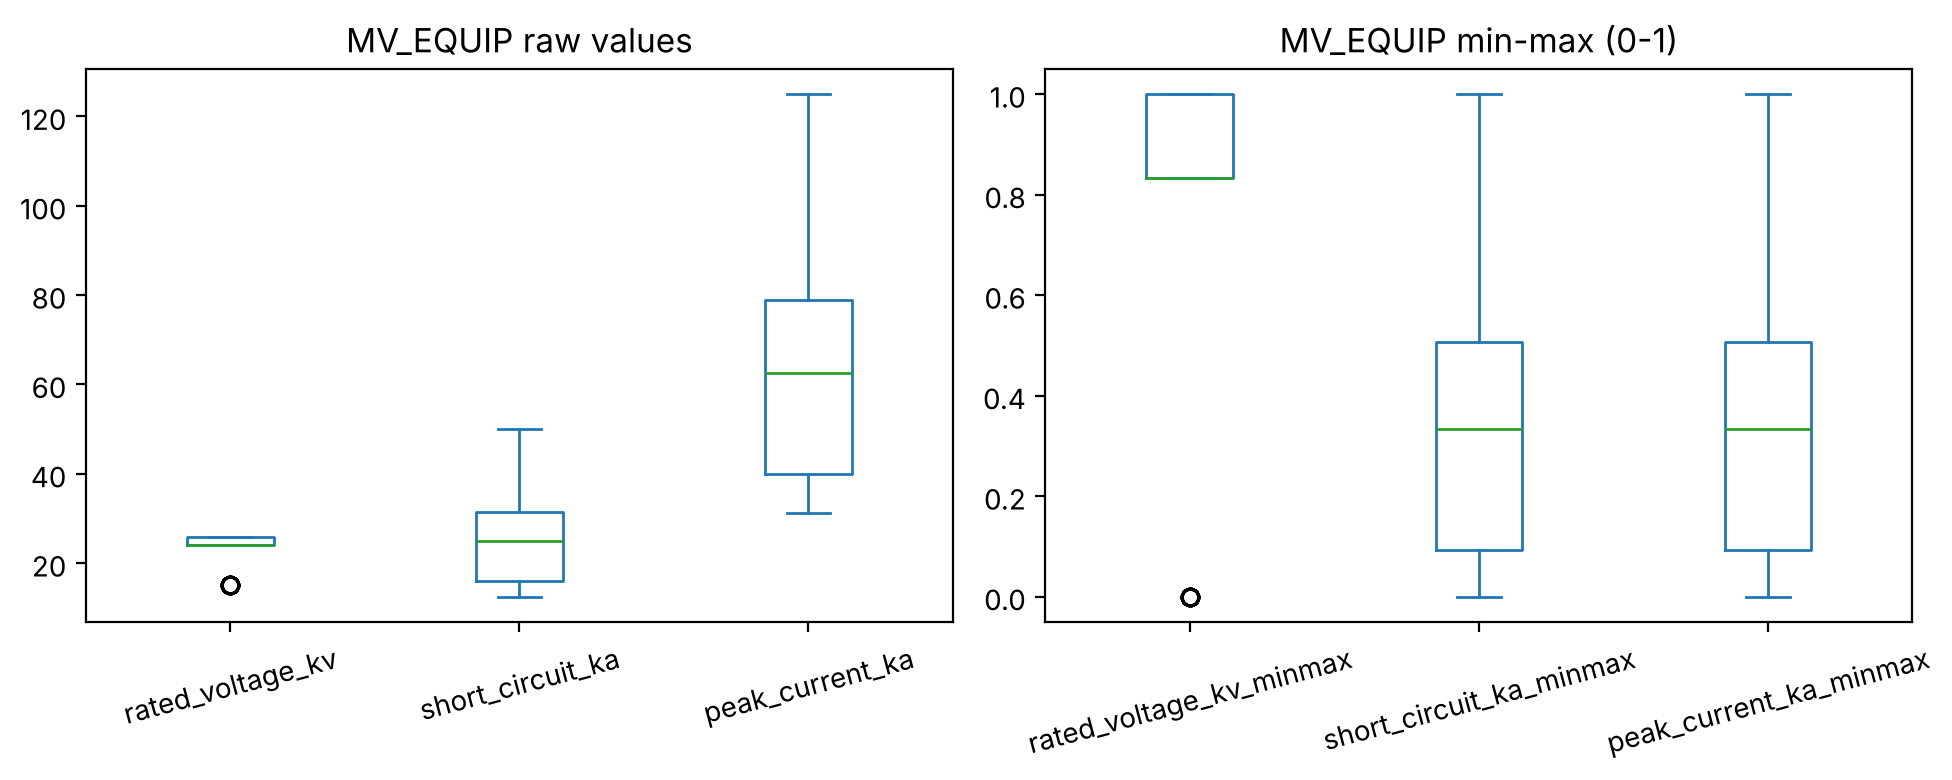

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
mv[["rated_voltage_kv", "short_circuit_ka", "peak_current_ka"]].plot.box(ax=axes[0])
axes[0].set_title("MV_EQUIP raw values")
mv[["rated_voltage_kv_minmax", "short_circuit_ka_minmax", "peak_current_ka_minmax"]].plot.box(ax=axes[1])
axes[1].set_title("MV_EQUIP min-max (0-1)")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.savefig(OUT / "normalization_mv_equip.png", dpi=120)
plt.show()

## 7. 전처리 전후 품질 비교와 저장

In [19]:
def unexplained_missing(frame):
    # 이유 표시가 없는 결측 셀 수
    flag_cols = [c for c in frame.columns if c.endswith("_missing") or c.endswith("_status")]
    base = frame.drop(columns=flag_cols, errors="ignore")
    total = int(base.isna().sum().sum())
    explained = 0
    if "rated_current_status" in frame:
        explained += int(frame["rated_current_a"].isna().sum())
    for c in [c for c in frame.columns if c.endswith("_missing")]:
        explained += int(frame[c].sum())
    return total - explained

kept_cols = [c for c in raw.columns if c not in all_empty]
quality = pd.DataFrame({
    "before": {
        "columns": raw.shape[1],
        "all_empty_columns": len(all_empty),
        "missing_cell_ratio_%": round(raw.isna().mean().mean() * 100, 1),
        "missing_cells_without_reason": int(raw.isna().sum().sum()),
        "broken_characters": broken_before,
        "numeric_columns": 0,
        "number_format_variants": sum(variants_before.values()),
        "rule_violations_checked": int((~rule1).sum() + (~rule2).sum()),
    },
    "after": {
        "columns": len(kept_cols),
        "all_empty_columns": 0,
        "missing_cell_ratio_%": round(df[kept_cols].isna().mean().mean() * 100, 1),
        "missing_cells_without_reason": unexplained_missing(df[kept_cols + [c for c in df.columns if c.endswith(("_missing", "_status"))]]),
        "broken_characters": broken_after,
        "numeric_columns": len(num_cols),
        "number_format_variants": 0,
        "rule_violations_checked": int((~rule1).sum() + (~rule2).sum()),
    },
})
quality

,before,after
columns,41.0,31.0
all_empty_columns,10.0,0.0
missing_cell_ratio_%,29.2,6.3
missing_cells_without_reason,1459.0,0.0
broken_characters,116.0,0.0
numeric_columns,0.0,15.0
number_format_variants,2.0,0.0
rule_violations_checked,0.0,0.0


- 결측 셀 비율이 크게 줄어든 주된 이유는 **값이 하나도 없던 10개 열을 분석본에서 뺐기 때문**입니다. 남은 결측은 지우거나 채우지 않았습니다.
- 대신 남은 결측 239칸 모두에 이유 표시 열(`*_missing`, `rated_current_status`)을 붙여, **이유를 모르는 결측이 0칸**이 되었습니다.
- 규칙 위반은 전후 모두 0건입니다. 정리 과정에서 값이 바뀌지 않았다는 확인이기도 합니다.

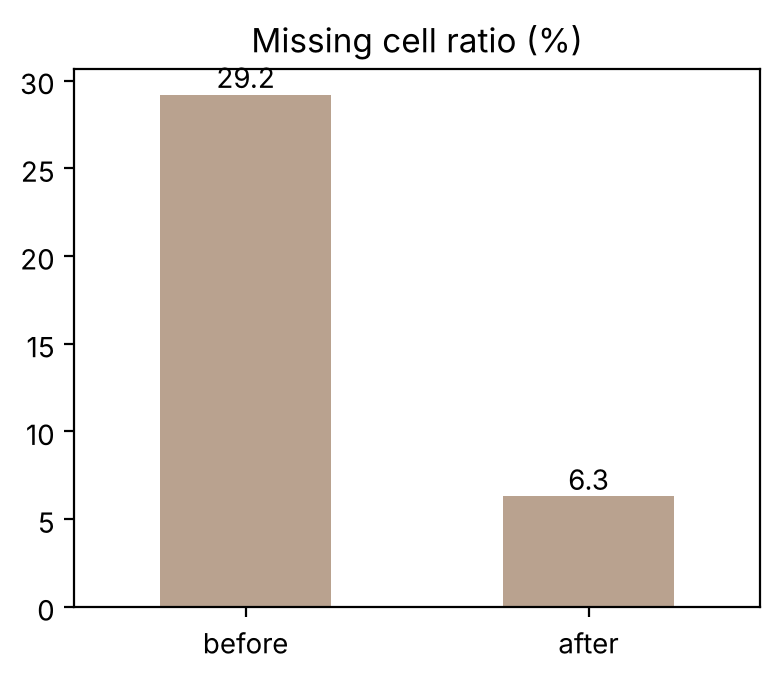

In [20]:
ax = quality.loc[["missing_cell_ratio_%"]].T.plot.bar(legend=False, color=["#b9a28f", "#5a7d8a"], figsize=(4, 3.5))
ax.set_title("Missing cell ratio (%)")
ax.set_xticklabels(["before", "after"], rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(OUT / "missing_before_after.png", dpi=120)
plt.show()

In [21]:
df.to_csv(OUT / "product_master_clean.csv", index=False, encoding="utf-8-sig")
quality.to_csv(OUT / "quality_report.csv", encoding="utf-8-sig")
missing.to_csv(OUT / "missing_before.csv", encoding="utf-8-sig")
print(df.shape)
sorted(p.name for p in OUT.iterdir())

(122, 51)


['missing_before.csv',
 'missing_before.png',
 'missing_before_after.png',
 'normalization_mv_equip.png',
 'product_master_clean.csv',
 'quality_report.csv']

## 정리

| 작업 | 결과 |
|---|---|
| 결측 원인 분류 | 수집 대상이 아닌 열 제거, 구조적 결측(SPD 정격 전류)과 수집 누락을 표시 열로 구분 |
| 결측 처리 원칙 | 사양값은 평균·중앙값으로 채우지 않음 (판정 근거가 지어낸 값이 되지 않도록) |
| 깨진 글자 | `째C` → `°C` 복구 |
| 형식 통일 | 숫자 열 숫자형 변환, 온도 범위를 최솟값·최댓값으로 분리, 여러 값 칸 정리 |
| 일관성 점검 | 투입 전류 = 피크 전류, 피크 ≈ 2.5 × 단시간 전류 규칙 점검 |
| 정규화 | 제품군 안 Min-Max·Z-score 열을 분석용으로 추가 (원래 값 유지) |